In [294]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

In [295]:
print(torch.__version__)
print(np.__version__)


2.14.1+cpu
2.5.3


In [296]:
a = torch.rand(30, 1)
x=a.numpy()
n = int(0.8 * len(x))
x_train, x_test = x[:n], x[n:]


In [297]:
x_train,x_test

(array([[0.5389899 ],
        [0.6672436 ],
        [0.93873173],
        [0.12445313],
        [0.37129086],
        [0.45641786],
        [0.8492071 ],
        [0.2723074 ],
        [0.34579682],
        [0.9928926 ],
        [0.56026053],
        [0.7395614 ],
        [0.06835985],
        [0.56590384],
        [0.65582305],
        [0.45682985],
        [0.04604095],
        [0.35996115],
        [0.5819777 ],
        [0.6507441 ],
        [0.48222065],
        [0.31318802],
        [0.2911697 ],
        [0.49145156]], dtype=float32),
 array([[0.3960272 ],
        [0.5103489 ],
        [0.75407344],
        [0.1521824 ],
        [0.7923443 ],
        [0.329364  ]], dtype=float32))

In [298]:
w=0.7
b=0.3
r=np.random.rand(len(x_train))*0.001
s=np.random.rand(len(x_test))*0.001

In [299]:
y_train,y_test=w*x_train+b,w*x_test+b

In [300]:
def graph(x_train,y_train,x_test,y_test):
    plt.scatter(x_train,y_train,c="g",label="train")
    plt.scatter(x_test,y_test,c="b",label="test")
    plt.legend()
    plt.show()

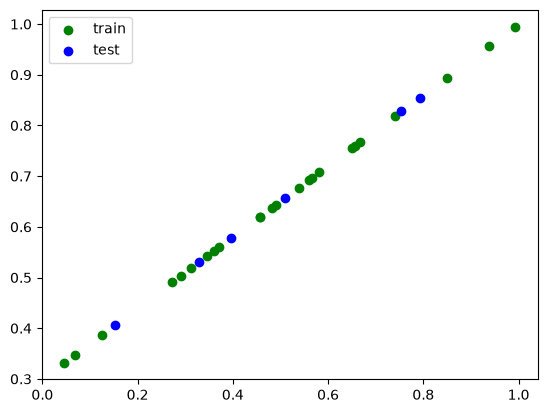

In [301]:
graph(x_train,y_train,x_test,y_test)

In [302]:
class LR(nn.Module):
    def __init__(self):
        super().__init__()
        self.liner=nn.Linear(1,1)
    def forward(self,x):
        return self.liner(x)

In [303]:
model=LR()

In [304]:
with torch.inference_mode():
    pred = model(torch.from_numpy(x_train))

In [305]:
pred

tensor([[0.5875],
        [0.5558],
        [0.4887],
        [0.6900],
        [0.6290],
        [0.6079],
        [0.5108],
        [0.6534],
        [0.6353],
        [0.4753],
        [0.5823],
        [0.5379],
        [0.7038],
        [0.5809],
        [0.5586],
        [0.6078],
        [0.7093],
        [0.6318],
        [0.5769],
        [0.5599],
        [0.6015],
        [0.6433],
        [0.6488],
        [0.5993]])

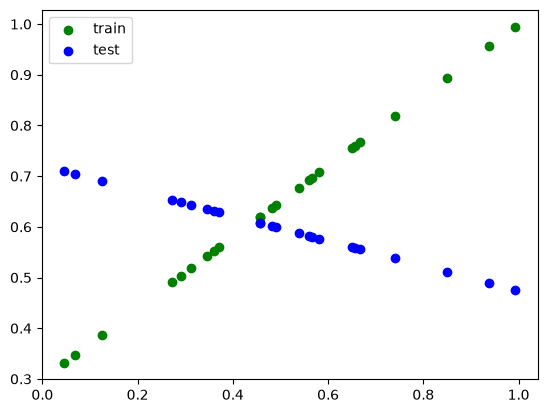

In [306]:
graph(x_train,y_train,x_train,pred.numpy())

In [315]:
epoch=2000
loss_fn=nn.L1Loss()
optimizer=torch.optim.SGD(model.parameters(),lr=0.001)
loss_mat=[]
for i in range(epoch):
    model.train()
    pred=model(torch.from_numpy(x_train))
    loss=loss_fn(pred,torch.from_numpy(y_train))
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    loss_mat.append(loss)
    print(f"epoch {i} | loss {loss}")


epoch 0 | loss 0.11354944109916687
epoch 1 | loss 0.11351921409368515
epoch 2 | loss 0.11348897963762283
epoch 3 | loss 0.1134587749838829
epoch 4 | loss 0.11342854052782059
epoch 5 | loss 0.11339833587408066
epoch 6 | loss 0.11336809396743774
epoch 7 | loss 0.11333787441253662
epoch 8 | loss 0.1133076474070549
epoch 9 | loss 0.11327741295099258
epoch 10 | loss 0.11324719339609146
epoch 11 | loss 0.11321697384119034
epoch 12 | loss 0.11318674683570862
epoch 13 | loss 0.1131565198302269
epoch 14 | loss 0.11312630027532578
epoch 15 | loss 0.11309608072042465
epoch 16 | loss 0.11306583881378174
epoch 17 | loss 0.11303562670946121
epoch 18 | loss 0.11300540715456009
epoch 19 | loss 0.11297518014907837
epoch 20 | loss 0.11294496059417725
epoch 21 | loss 0.11291474103927612
epoch 22 | loss 0.11288449913263321
epoch 23 | loss 0.11285427212715149
epoch 24 | loss 0.11282406002283096
epoch 25 | loss 0.11279382556676865
epoch 26 | loss 0.11276361346244812
epoch 27 | loss 0.1127333715558052
epoch 

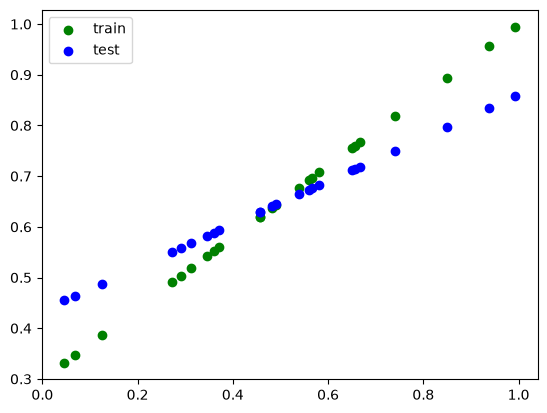

In [316]:
with torch.inference_mode():
    graph(x_train,y_train,x_train,model(torch.from_numpy(x_train)).numpy())

In [317]:
with torch.inference_mode():
    loss_list=[]
    for i in loss_mat:
        loss_list.append(i.numpy())

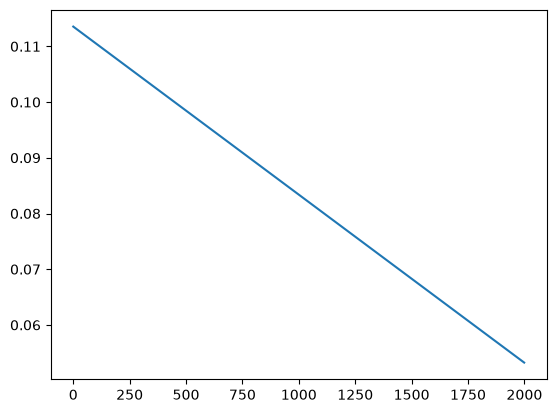

In [318]:
plt.plot(loss_list)
plt.show()